# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

Prof Luis Eduardo Falcón Morales

Actividad de Semana 3

### **Rotación de Personal - IBM**

* **Nombre:** Adrián Aguilar Sánchez

* **matrícula:** A01651592

------------

* #### **En esta actividad puedes apoyarte en uno o varios Modelos de Lenguaje de Gran Tamaño, LLM por sus siglas en inglés (Large Language Model). Indica claramente cuál o cuáles utilizaste.**

* #### **La siguiente actividad se basa en los datos del archivo "WA_Fn-UseC_-HR-Employee-Attrition.csv" que se encuentra en la siguiente liga de Kaggle, llamada "IBM HR Analytics Employee Attrition & Performance".**

* #### **Los datos los proporcionó IBM y aunque comentaron que por cuestiones de privacidad los datos son sintéticos, los generaron con base a su experiencia. Estos datos en general son referencia cuando se habla en Estadística o Aprendizaje Automático sobre el tema de rotación de personal.**

**El archivo contiene 1470 registros:**

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset


# **Ejercicio 1:**

#### **Incluye una breve introducción sobre lo que se entiende por el problema de rotación de personal en las organizaciones (employee attrition problem).**

El employee attrition problem ocurre cuando la fuerza laboral de una institiución disminuye de manera gradual de forma natural (por renuncia, retiro, despido) y la institución decide no reemplazar a este personal.

In [247]:
# Agrega aquí todas las librerías adicionales o paquetes que consideres necesarias:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report



* #### **Descarga el archivo de datos de la página de Kaggle.**

* #### **Cargamos el archivo como un DataFrame de Pandas y hacemos uso del método “describe” con el argumento include= “all” para desplegar información de todas las variables, numéricas y categóricas.**

In [248]:
import kagglehub
import os

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
csv_path = os.path.join(path, "WA_Fn-UseC_-HR-Employee-Attrition.csv")
data = pd.read_csv(csv_path)

print("Tamaño del DataFrame:", data.shape)
data.describe(include = 'all').T


Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Tamaño del DataFrame: (1470, 35)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


# **Ejercicio 2:**

**a) Realiza los análisis descriptivos y/o gráficos que creas adecuados para identificar 4 factores que se deben eliminar desde un inicio.**

**Al nuevo DataFrame sin las variables indicadas, llamarlo df.**



In [249]:
# a) Incluye a continuación el código y celdas que creas adecuados para responder a la pregunta.
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [250]:
n_duplicados = data.duplicated().sum()
print(f"Registros duplicados encontrados: {n_duplicados}")

Registros duplicados encontrados: 0


In [251]:
data.nunique()

,0
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EmployeeCount,1
EmployeeNumber,1470


In [252]:
df = data.drop(columns=['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'])


# Verifiquemos de qué tamaño queda el nuevo DataFrame:
print("Tamaño del nuevo DataFrame:", df.shape)

Tamaño del nuevo DataFrame: (1470, 31)


**b) Con base a tu análisis anterior, indica cuáles fueron estas 4 variables y la justificación de por qué se pueden eliminar.**

Se eliminaron las variables 'EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'por las siguientes razones:


*   EmployeeCount: el valor es constante para todos los registros y, por lo tanto, no tiene capacidad predictiva
*   EmployeeNumber: no tiene capacidad predictiva esta variable porque es única para cada registro
*   Over18: el valor es constante para todos los registros y, por lo tanto, no tiene capacidad predictiva
*   StandardHours: el valor es constante para todos los registros y, por lo tanto, no tiene capacidad predictiva





# **Ejercicio 3:**

#### **Una vez eliminadas las variables no deseadas, clasifiquemos las restantes como se indica a continuación y en base a la información dada en la plataforma de Kaggle.**

#### **El número entre corcheas indica el número de variables de dicho tipo y el  número entre paréntesis redondos indica el número de niveles.**

* **Variables numéricas [14]:**

   * NumCompaniesWorked

   * TrainingTimesLastYear

   * Age

   * DailyRate

   * DistanceFromHome

   * HourlyRate

   * MonthlyIncome

   * MonthlyRate

   * PercentSalaryHike

   * TotalWorkingYears

   * YearsAtCompany

   * YearsInCurrentRole

   * YearsSinceLastPromotion

   * YearsWithCurrManager

* **Variables ordinales [9]:**

   * Education (5)

   * EnvironmentSatisfaction (4)

   * JobInvolvement (4)

   * JobLevel (5)

   * JobSatisfaction (4)

   * PerformanceRating (2)

   * RelationshipSatisfaction (4)

   * StockOptionLevel (4)

   * WorkLifeBalance (4)

* **Variables binarias [3]:**

   * Attrition (variable de salida)

   * Gender

   * OverTime

* **Variables nominales [5]:**

   * BusinessTravel (3)

   * Department (3)

   * EducationField (6)

   * JobRole (9)

   * MaritalStatus (3)

**Indpendientemente de los factores que al final el modelo identifique como los factores más importantes a considerar en este problema de rotación de personal ¿qué preocupaciones éticas o legales podrían generarse, si algunos de estos factores más importantes a considerar para tomar decisiones sobre los empleados fueran la edad (Age), el género (Gender) o el estado civil (Marital Status)?**


El problema principal es que si se toman en cuenta esos factores como los más importantes para resolver el problema de la rotación de personal se podría incurrir en actos de discriminación: se perfilaría a una persona por aspectos biológicos o preferencias personales que no deberían tener relación con su desempeño laboral, dejando a la institución en una situación delicada en términos éticos y legales.

# **Ejercicio 4:**

**a) Aunque este problema como está planteado es un problema de clasificación binaria, ¿qué otros enfoques analíticos podrían plantearse y modelarse a partir de este problema? Menciona al menos dos más.**





1.   Puede pensarse como un problema que también tiene una dimensión temporal, de modo que no sólo respondería a la pregunta de quién eestá en riesgo de salir, sino de cuándo una persona puede salir. Esto se puede obtener con los datos relativos a los años que una persona ha trabajado en la empresa. Para ello se plantea el uso de modelos de Riesgos Proporcionales de Cox (Cox Proportional Hazards), Curvas de Kaplan-Meier o Modelos Paramétricos de Supervivencia
2.   Pueden ser pensado como un problema de clustering, en el que se agrupa a los empleados de acuerdo a sus patrones de comportamiento para determinar los perfiles de personas en riesgo de dejar la institución y, con base en ello, plantear diferentes estrategias para cada segmento para retener a los empleados.



### **Para esta actividad usaremos una partición en Train, Val y Test, con los porcentajes que se indican a continuación.**

In [253]:
print("Dimensiones y Porcentajes de la partición Train+Validation+Test generada:")
print("-"*75)

X = df.drop(columns='Attrition')
y = df[['Attrition']]

Xtrain, Xtv, ytrain, ytv = train_test_split(X, y, train_size=0.70, stratify=y, random_state=17)
Xval, Xtest, yval, ytest = train_test_split(Xtv, ytv, test_size=0.5, stratify=ytv, random_state=17)

print("Variables de entrada Train, Validation, Test:")
print(Xtrain.shape, '%.1f%%' % (100.*Xtrain.shape[0]/X.shape[0]))
print(Xval.shape, '%.1f%%' % (100.*Xval.shape[0]/X.shape[0])),
print(Xtest.shape, '%.1f%%' % (100.*Xtest.shape[0]/X.shape[0]))

print("\nVariables de salida Train, Validation, Test:")
print(ytrain.shape)
print(yval.shape)
print(ytest.shape)

Dimensiones y Porcentajes de la partición Train+Validation+Test generada:
---------------------------------------------------------------------------
Variables de entrada Train, Validation, Test:
(1029, 30) 70.0%
(220, 30) 15.0%
(221, 30) 15.0%

Variables de salida Train, Validation, Test:
(1029, 1)
(220, 1)
(221, 1)


# **Ejercicio 5:**


**a) Aplica la transformación LabelEncoder() de Sklearn a la variable“Attrition”, tomando en cuenta los siguientes puntos:**

* **Las nuevas variables deberán llamarse ahora: ytrainT, yvalT, ytestT.**

* **Al aplicar la transformación LabelEncoder deberás evitar el filtrado de información (data-leakage).**


In [254]:
# a)

le = LabelEncoder()
ytrainT = le.fit_transform(ytrain.values.ravel())
yvalT = le.transform(yval.values.ravel())
ytestT = le.transform(ytest.values.ravel())


print('Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):\n', pd.Series(ytrainT).value_counts() / ytrainT.shape[0])

Porcentaje de datos en cada clase del conjunto de entrenamiento (Train):
 0    0.838678
1    0.161322
Name: count, dtype: float64


#### Además, responde las siguientes preguntas:

**b) Con base a la documentación actual de Sklearn, ¿a qué tipo de variables se recomienda aplicar la transformación LabelEncoder?**

**c) Con base al contexto del problema, ¿qué significan los valores 0 (NO) y 1 (YES) de la variable de salida Attrition?**

**d) Con base a la información obtenida y considerando la métrica de la exactitud (accuracy) ¿cuál será el valor del umbral del modelo base o ingenuo (baseline, naive) a superar para evitar tener un modelo subentrenado una vez que empecemos a generarlos?**

**e) Indica si el desbalanceo de clases obtenido puede ya considerarse como un problema, y de considerarlo así, qué otra métrica o métricas podrían ser más adecuadas que la exactitud (accuracy).**




b) Ese transformador debe usarse para codificar valores objetivo, es decir "y", y no la entrada "x"
c) El valor 1 quiere decir que esa persona ya no trabaja en la institución, mientras que 0 significa que sigue trabajando ahí  

d) La superación de la exactitud de un modelo base implica que las probabilidades de predecir correctamente la clase mayoritaria debe ser mayor que su precisión base, definida por:

 $$\text{Accuracy}_{\text{base}} = \frac{\text{Casos de la Clase Mayoritaria}}{\text{Total de Casos}} = \frac{1233}{1470} \approx \mathbf{0.8388} \text{ o } \mathbf{83.9\%}$$

Este porcentaje indica que un modelo que prediga que "nadie va a renunciar"(la clase mayoritaria) para todas sus predicciones, tendría una precisión de casi el 84%
e) El desbalanceo de clases representa un problema  porque distorsiona la exactitud, permitiendo que un modelo  sin capacidad predictiva alcance un 83.9% de acierto simplemente prediciendo que ningún empleado renunciará. Para evaluar correctamente el desempeño sobre la clase minoritaria (Attrition = 1) y evitar falsos negativos, es indispensable sustituir o complementar la exactitud con métricas como el Recall (sensibilidad para detectar fugas de talento), el F1-Score (balance entre precisión y recall) y el PR-AUC (área bajo la curva Precisión-Recall).

# **Ejercicio 6:**


#### **Incluye a continuación un análisis gáfico y descriptivo que consideres adecuado.**

  * **a) El análisis debe ser suficiente para que te ayude a tomar las decisiones sobre qué transformaciones aplicar a cada variable antes de entrenar los modelos.**

  * **b) Además, para obtener mayor información sobre la relación entre variables, incluye un gráfico de barras de frecuencias ordenadas de mayor a menor, de la variable "Age", únicamente para los casos de empleados que ya no están en la compañía (Attrition=Yes).**

  * **c) Incluye también un gráfico de barras ordenado de la relación entre Education y Attrition=Yes. Muestra además en el gráfico las etiquetas asociadas a Education en lugar de los números, como se indica en la página de Kaggle.**

  * **d) [Opcional] Incluye algún otro gráfico o gráficos que consideres aporta información para el análisis y entendimiento del problema. Si no encuentras algún otro gráfico de interés, deberas indicarlo.**

  * **e) Para la empresa de IBM ¿qué es más costoso? ¿clasificar erróneamente a un empleado que sí renunciará, o por el contrario, generar una falsa alarma?**


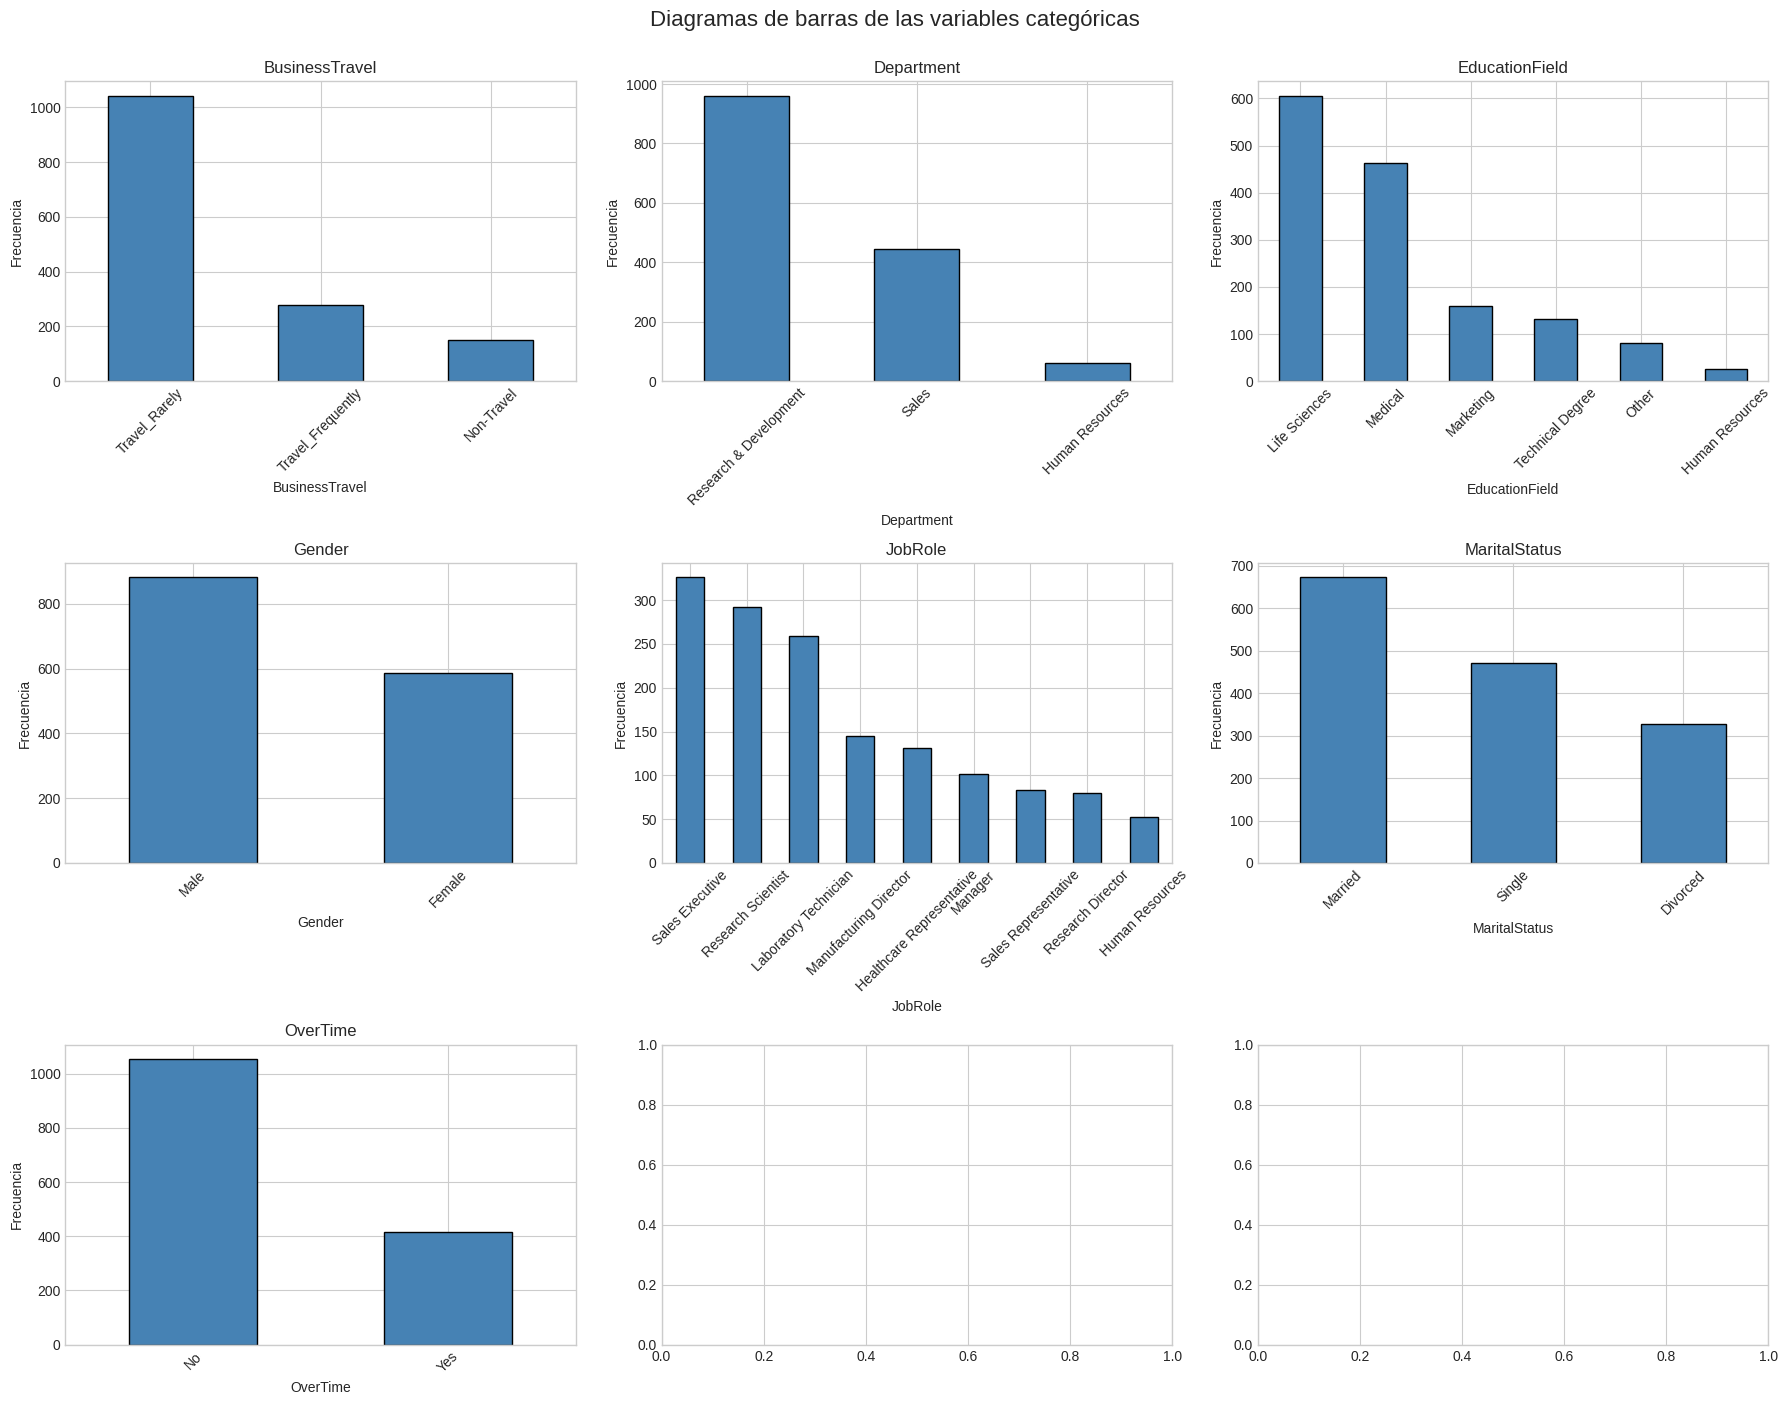

In [255]:
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    df[col].value_counts().plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(col)
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=45)
plt.suptitle('Diagramas de barras de las variables categóricas', y=1.0, fontsize=16)
plt.tight_layout()
plt.show()


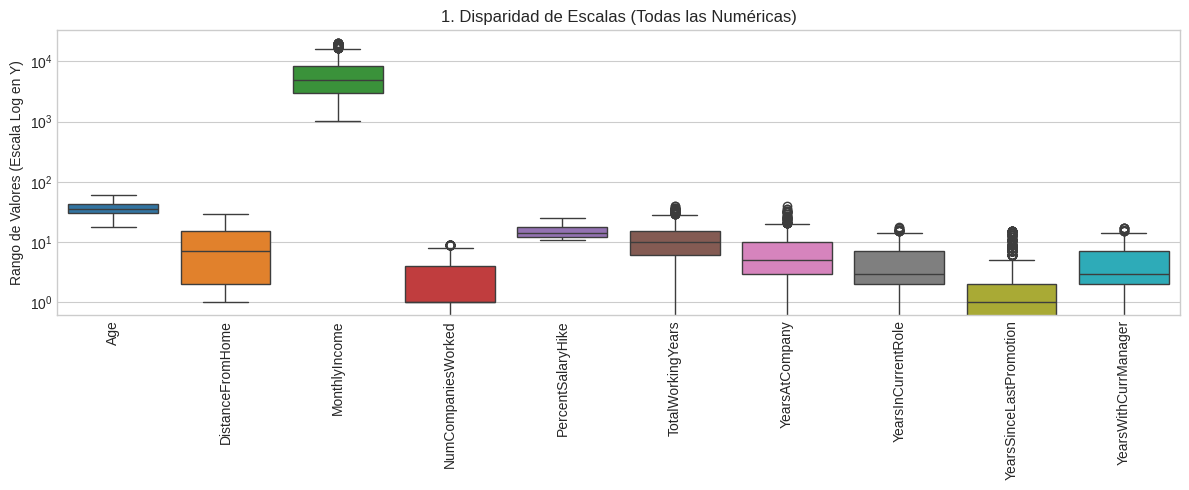

In [256]:

# 1. DISPARIDAD DE ESCALAS: Todas las variables numéricas continuas/discretas principales
cols_numericas = [
    'Age',
    'DistanceFromHome',
    'MonthlyIncome',
    'NumCompaniesWorked',
    'PercentSalaryHike',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager',
]

plt.figure(figsize=(12, 5))
ax = sns.boxplot(data=Xtrain[cols_numericas])
ax.set_yscale('log')  # Escala logarítmica solo para comparar rangos
ax.set_title('1. Disparidad de Escalas (Todas las Numéricas)')
ax.tick_params(axis='x', rotation=90)
ax.set_ylabel('Rango de Valores (Escala Log en Y)')
plt.tight_layout()
plt.show()

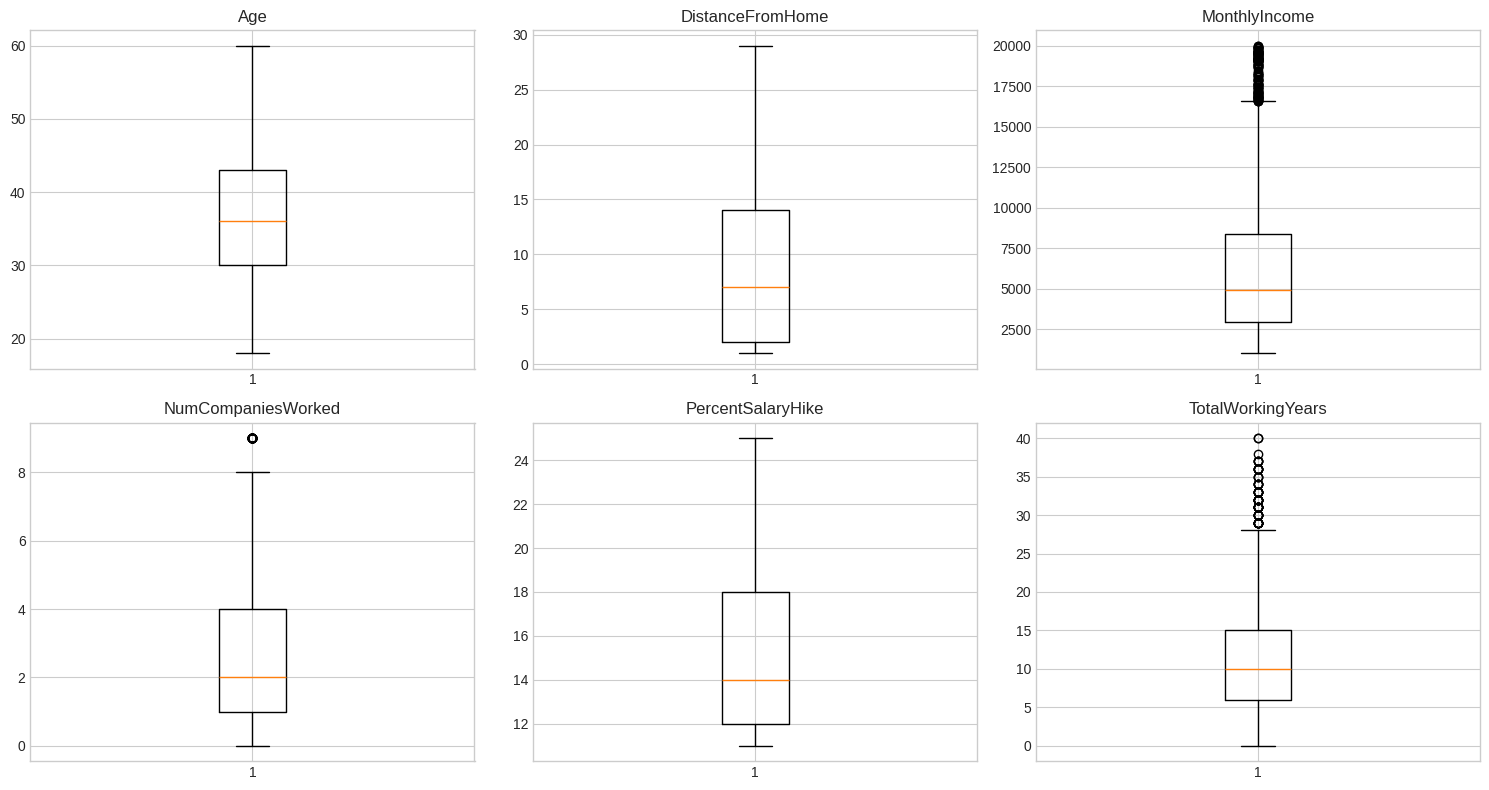

In [257]:
import matplotlib.pyplot as plt

num_cols = ["Age", "DistanceFromHome", "MonthlyIncome", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)


for ax in axes[len(num_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

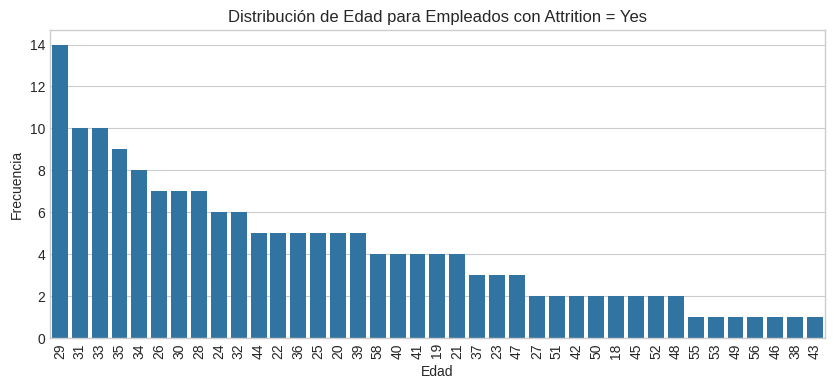

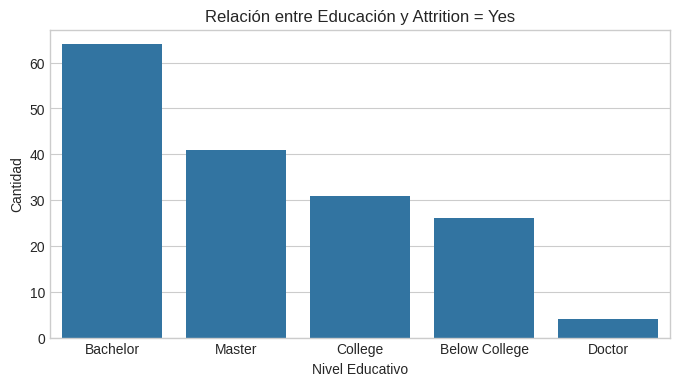

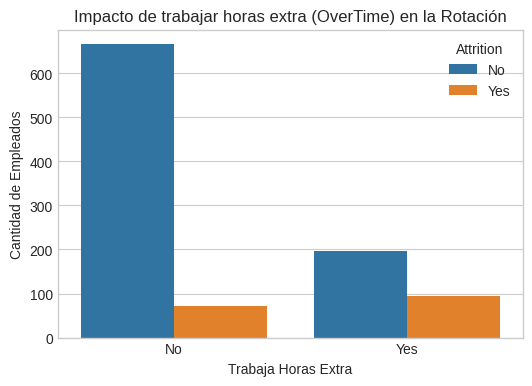

In [258]:
# b) Gráfico age-attrition[yes]
plt.figure(figsize=(10, 4))
# Filtramos en Xtrain usando el índice de ytrain que tenga 'Yes'
edades_attrition_yes = Xtrain.loc[ytrain['Attrition'] == 'Yes', 'Age']
sns.countplot(x=edades_attrition_yes, order=edades_attrition_yes.value_counts().index)
plt.title('Distribución de Edad para Empleados con Attrition = Yes')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.xticks(rotation=90)
plt.show()

# c) Gráfico education-attrition[yes]
# Mapeo de niveles educativos según Kaggle:
# 1 'Below College', 2 'College', 3 'Bachelor', 4 'Master', 5 'Doctor'
edu_map = {1: 'Below College', 2: 'College', 3: 'Bachelor', 4: 'Master', 5: 'Doctor'}
Xtrain_edu = Xtrain.copy()
Xtrain_edu['Education_Label'] = Xtrain_edu['Education'].map(edu_map)

plt.figure(figsize=(8, 4))
educacion_attrition_yes = Xtrain_edu.loc[ytrain['Attrition'] == 'Yes', 'Education_Label']
sns.countplot(x=educacion_attrition_yes, order=educacion_attrition_yes.value_counts().index)
plt.title('Relación entre Educación y Attrition = Yes')
plt.xlabel('Nivel Educativo')
plt.ylabel('Cantidad')
plt.show()

# d) Relación de OverTime (Horas extra) con Attrition
plt.figure(figsize=(6, 4))
sns.countplot(data=Xtrain.assign(Attrition=ytrain['Attrition']), x='OverTime', hue='Attrition')
plt.title('Impacto de trabajar horas extra (OverTime) en la Rotación')
plt.xlabel('Trabaja Horas Extra')
plt.ylabel('Cantidad de Empleados')
plt.show()

**e) ¿Qué es más costoso, los Falsos Negativos o los Falsos Positivos?**

los Falsos Negativos (FN) son más costosos que los Falsos Positivos (FP). Un Falso Negativo ocurre cuando el modelo asume que un empleado se quedará pero termina renunciando, lo que le cuesta más a la empresa debido a gastos imprevistos de reclutamiento, pérdida de conocimientos, capacitación y vacantes no cubiertas, mientras que un Falso Positivo solo implica el costo mínimo de activar una estrategia de retención preventiva (como una entrevista o un incentivo menor) para alguien que no pensaba irse.

# **Ejercicio 7:**

#### **Utiliza las clases Pipeline y ColumnTransformer de Sklearn para definir las transformaciones que deberás aplicar a cada variable y de acuerdo a su tipo considerado previamente.**



In [259]:
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

cols_numericas = [
    'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
    'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany',
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager',
]

# 9 ordinales
cols_ordinales = [
    'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
    'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
    'StockOptionLevel', 'WorkLifeBalance',
]

# Binarias de entrada (Attrition es la salida)
cols_binarias = ['Gender', 'OverTime']

# 5 nominales (antes faltaba BusinessTravel)
cols_nominales = ['BusinessTravel', 'Department', 'EducationField',
                  'JobRole', 'MaritalStatus']

# 1. Numéricas: log1p + estandarización
numericas_pipeline = Pipeline(steps=[
    ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scaler', StandardScaler()),
])

# 2. Ordinales: estandarización (para que KNN y la regularización las traten en la misma escala)
catOrd_pipeline = Pipeline(steps=[('scaler', StandardScaler())])

# 3. Binarias
catBin_pipeline = Pipeline(steps=[
    ('onehot_bin', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# 4. Nominales
catNom_pipeline = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

columnasTransformer = ColumnTransformer(
    transformers=[
        ('num', numericas_pipeline, cols_numericas),
        ('ord', catOrd_pipeline, cols_ordinales),
        ('bin', catBin_pipeline, cols_binarias),
        ('nom', catNom_pipeline, cols_nominales),
    ],
    remainder='drop',
)

* #### **Vamos a utilizar validación cruzada, por lo que decidimos para esta actividad reagrupar los conjuntos de entrenamiento y validación en un solo DataFrame.**

* #### **Al resultado obtenido los llamaremos Xtv y ytv.**


In [260]:
Xtv = pd.concat([Xtrain, Xval], axis=0)
ytv = np.concatenate([ytrainT, yvalT], axis=0)

print("Dimensión del conjunto Train+Val:")
print(Xtv.shape)
print(ytv.shape)

Dimensión del conjunto Train+Val:
(1249, 30)
(1249,)


# **Ejercicio 8:**

#### **Entrenamiento y ajuste de hiperparámetros**

#### **a) Busca los mejores hiperparámetros para cada modelo, de manera que no estén subentrenados con respecto a la métrica de la exactitud (accuracy).**

#### **b) Incluye tus comentarios sobre el resultado obtenido.**



#### **NOTA-1: En dado caso, cuando mucho uno de los modelos podría quedar subentrenado.**

#### **NOTA-2: Por el momento estamos usando la métrica de la exactitud (accuracy). El objetivo de esta actividad es que sepas entrenar modelos sin que resulten subentrenados o sobreentrenados, independientemente de la métrica a considerar. En próximas semanas seguiremos con el estudio de las otras métricas para abordar de mejor manera los problemas y obtener mejores resultados.**

En relación a la variante de Validación Cruzada "RepeatedStratifiedKFold" utilizada en este ejercicio, puedes consultar la siguiente liga:

  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RepeatedStratifiedKFold.html


>> LR 0.890 (0.015)
>> LASSO 0.870 (0.010)
>> RIDGE 0.886 (0.014)
>> EN 0.879 (0.012)
>> KNN 0.843 (0.007)


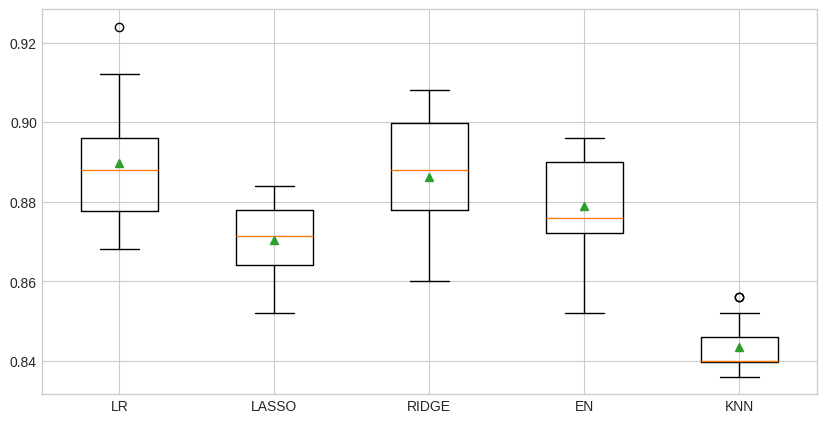

In [261]:
# 8a) Ajuste de hiperparámetros.
#     En cada modelo que utilcemos a continuación, utiliza la semilla "random_state=1"
#     indicada, para obtener la repetibilidad de los resultados en la manera de lo
#     posible. Es decir, este argumento y valor no deberás modificarlo.



def mis_modelos():
    modelos, nombres = list(), list()

    # LR sin regularización
    modelos.append(LogisticRegression(
        penalty=None, solver='lbfgs', max_iter=2000, random_state=1))
    nombres.append('LR')

    # Lasso (L1)
    modelos.append(LogisticRegression(
        penalty='l1', solver='saga', C=0.1, max_iter=5000, random_state=1))
    nombres.append('LASSO')

    # Ridge (L2)
    modelos.append(LogisticRegression(
        penalty='l2', solver='lbfgs', C=0.1, max_iter=2000, random_state=1))
    nombres.append('RIDGE')

    # Elastic Net
    modelos.append(LogisticRegression(
        penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.1,
        max_iter=5000, random_state=1))
    nombres.append('EN')

    # KNN con más vecinos
    modelos.append(KNeighborsClassifier(
        n_neighbors=25, weights='uniform', metric='minkowski', p=2))
    nombres.append('KNN')

    return modelos, nombres



# Pasamos al entrenamiento de los modelos.
# Hay obviamente varias maneras de llevar a cabo el entrenamiento,
# pero por el momento supongamos que lo hacemos de la manera siguiente:

modelos, nombres = mis_modelos()  # accesando los modelos.
resultados = list()    # para guardar los resultados en esta lista.

# Iterando y entrenando sobre cada modelo:
for i in range(len(modelos)):

  pipeline = Pipeline(steps=[('ct',columnasTransformer),('m',modelos[i])])   # Conjuntamos Transformaciones y modelos en un Pipeline.

  cv1 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)     # Aplicando una de las variantes de Validación Cruzada.

  scores = cross_val_score(pipeline, Xtv, np.ravel(ytv), scoring='accuracy', cv=cv1)   # Entrenando y generando los resultados con la exactitud (accuracy).


  resultados.append(scores)    # Guardamos los resultados en la lista.
  print('>> %s %.3f (%.3f)' % (nombres[i], np.nanmean(scores), np.nanstd(scores)))  # Desplegando los promedios de cada modelo.


plt.figure(figsize=(10,5))
plt.boxplot(resultados, tick_labels=nombres, showmeans=True)   # Gráficos de caja para una comparación visual de los resultados.
plt.show()


**8b) Comentarios sobre los resultados y modelos obtenidos. En particular indica cuál consideras el mejor modelo. ¿Alguno quedó subentrenado y ya no se pudo mejorar su desempeño?**

Los cuatro modelos de regresión logística superaron  el umbral del modelo
ingenuo (accuracy = 0.8388): LR obtuvo una exactitud promedio de aprox. 0.890, Ridge
0.886, Elastic Net 0.879 y Lasso 0.870
Las diferencias entre LR y Ridge son muy pequeñas y menores que su desviación estándar
entre repeticiones, por lo que son estadísticamente equivalentes en la práctica.

KNN (k=21) quedó con una exactitud de aprox. 0.843, apenas 0.4 puntos sobre el baseline,
con una mediana (0.840) prácticamente igual a él. Lo considero el modelo subentrenado: aun
ajustando el número de vecinos no logró separar de forma útil las clases.


# **Ejercicio 9:**

* #### **Utiliza el mejor modelo encontrado en el paso anterior, los datos Xtv, ytv, y realiza ahora una búsqueda de malla con validación cruzada para tratar de mejorar el desempeño de este modelo.**

* #### **Sigue utilizando la métrica de la exactitud (accuracy).**

* #### **Verifica además que el modelo no esté subentrenado o sobreentrenado.**

* #### **Llama "resultado_malla" al mejor modelo ajustado.**




* **NOTA-1: Para esta actividad diremos que el modelo no está sobreentrenado si la diferencia entre Train y Validation es menor al 3%.**


* **NOTA-2: Puedes utilizar GridSearchCV, o bien, RandomizedSearchCV. La documentación la puedes consultar en las siguientes ligas:**

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html


In [262]:

pipeline_final = Pipeline(steps=[
    ('ct', columnasTransformer),
    ('m', LogisticRegression(penalty='l2', solver='lbfgs',
                             max_iter=2000, random_state=1)),
])

# Malla de hiperparámetros
param_grid = {'m__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}

cv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)

malla = GridSearchCV(
    estimator=pipeline_final,
    param_grid=param_grid,
    scoring='accuracy',
    cv=cv2,
    n_jobs=-1,
    return_train_score=True,   # necesario para mean_train_score en el print
    refit=True,
)
malla.fit(Xtv, ytv)

resultado_malla = malla



print("Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)")
print("-"*65)
print("Mejor modelo: %f usando los hiperparámetros %s" % (resultado_malla.best_score_, resultado_malla.best_params_))
print('Promedios Train mean(std): %.2f%% (%.4f%%)' % (100*np.nanmean(resultado_malla.cv_results_['mean_train_score']),
                                                 100*np.nanmean(resultado_malla.cv_results_['std_train_score'])))
print('Promedios Val mean(std): %.2f%% (%.4f%%)' % (100*resultado_malla.cv_results_['mean_test_score'].mean(),
                                               100*resultado_malla.cv_results_['std_test_score'].mean()))

Desempeño del mejor modelo con la métrica de Exactitud (Accuracy)
-----------------------------------------------------------------
Mejor modelo: 0.891381 usando los hiperparámetros {'m__C': 0.3}
Promedios Train mean(std): 89.57% (0.4371%)
Promedios Val mean(std): 88.29% (1.4428%)


# **Ejercicio 10:**

#### **Finalmente, usando el conjunto de prueba (Test) responde los siguientes incisos:**

#### **a) Obtener el desempeño final del mejor modelo con el reporte de métricas classification_report() de Sklearn.**

#### **b) Obtener la matriz de confusión del mejor modelo.**

#### **c) Indica como se leen o interpretan los valores VP, VN, FP, FN obtenidos y de acuerdo al contexto del problema.**

#### **d) Realiza un análisis de importancia de los factores o características e incluye tus comentarios.**



In [263]:
# a) Reporte del desempeño con classification_report():

ypred = resultado_malla.predict(Xtest)

print(classification_report(ytestT, ypred, target_names=['No', 'Yes']))


              precision    recall  f1-score   support

          No       0.89      0.96      0.93       185
         Yes       0.68      0.42      0.52        36

    accuracy                           0.87       221
   macro avg       0.79      0.69      0.72       221
weighted avg       0.86      0.87      0.86       221



[[178   7]
 [ 21  15]]


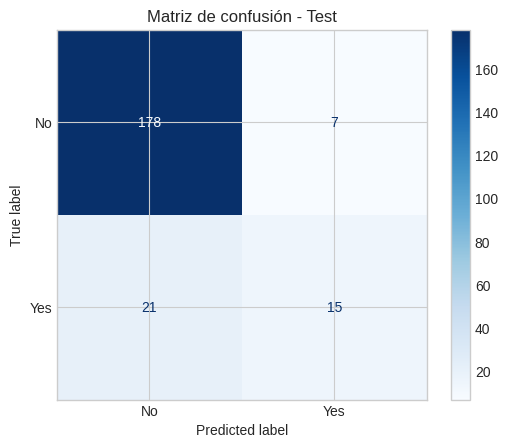

VN=178  FP=7  FN=21  VP=15


In [264]:
from sklearn.metrics import confusion_matrix
# b) Matriz de confusión:
cm = confusion_matrix(ytestT, ypred)
print(cm)

ConfusionMatrixDisplay.from_predictions(
    ytestT, ypred, display_labels=['No', 'Yes'], cmap='Blues'
)
plt.title('Matriz de confusión - Test')
plt.show()

VN, FP, FN, VP = cm.ravel()
print(f"VN={VN}  FP={FP}  FN={FN}  VP={VP}")


*  c) Interpretación de VP, VF, FP, FN.

* **VP:** empleados que el modelo predijo que renunciarían y efectivamente renunciaron.

* **VN:** empleados que el modelo predijo que se quedarían y efectivamente se quedaron.

* **FP:** empleados que el modelo predijo que renunciarían pero se quedaron.

* **FN:** empleados que el modelo predijo que se quedarían pero renunciaron.

Modelo: LogisticRegression(C=0.3, max_iter=2000, random_state=1)
Top 15 por magnitud del coeficiente:
                              feature   coef  odds_ratio
                    bin__OverTime_Yes  1.854       6.383
nom__BusinessTravel_Travel_Frequently  1.189       3.285
            nom__MaritalStatus_Single  0.763       2.144
   nom__JobRole_Laboratory Technician  0.561       1.753
         ord__EnvironmentSatisfaction -0.497       0.608
              num__NumCompaniesWorked  0.482       1.620
                  ord__JobInvolvement -0.442       0.643
              num__YearsInCurrentRole -0.426       0.653
         num__YearsSinceLastPromotion  0.419       1.520
                   num__MonthlyIncome -0.412       0.662
                  num__YearsAtCompany  0.412       1.510
                 ord__JobSatisfaction -0.409       0.664
 nom__EducationField_Technical Degree  0.402       1.495
                num__DistanceFromHome  0.385       1.470
      nom__JobRole_Research Scientist -0.38

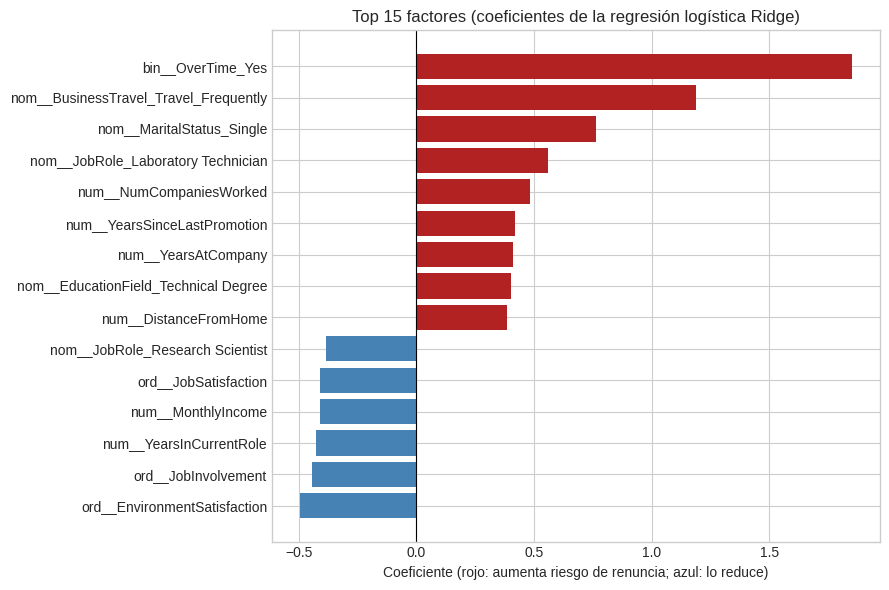


Top 10 por permutación (caída en ROC-AUC):
                feature  caida_AUC    std
YearsSinceLastPromotion     0.0283 0.0101
     NumCompaniesWorked     0.0267 0.0090
          MonthlyIncome     0.0246 0.0111
      TotalWorkingYears     0.0246 0.0075
               OverTime     0.0215 0.0175
   YearsWithCurrManager     0.0188 0.0097
     YearsInCurrentRole     0.0187 0.0119
          MaritalStatus     0.0109 0.0086
        WorkLifeBalance     0.0106 0.0054
        JobSatisfaction     0.0105 0.0092


In [265]:
from sklearn.inspection import permutation_importance

mejor_pipeline = resultado_malla.best_estimator_
print("Modelo:", mejor_pipeline.named_steps['m'])

nombres_features = mejor_pipeline.named_steps['ct'].get_feature_names_out()
coefs = mejor_pipeline.named_steps['m'].coef_.ravel()

# --- 1) Coeficientes
imp = pd.DataFrame({'feature': nombres_features, 'coef': coefs})
imp['abs_coef'] = imp['coef'].abs()
imp['odds_ratio'] = np.exp(imp['coef'])
imp = imp.sort_values('abs_coef', ascending=False)

print("Top 15 por magnitud del coeficiente:")
print(imp.head(15)[['feature', 'coef', 'odds_ratio']].round(3).to_string(index=False))

top = imp.head(15).sort_values('coef')
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['coef'],
         color=['firebrick' if c > 0 else 'steelblue' for c in top['coef']])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 factores (coeficientes de la regresión logística Ridge)')
plt.xlabel('Coeficiente (rojo: aumenta riesgo de renuncia; azul: lo reduce)')
plt.tight_layout()
plt.show()

# --- 2) Permutación sobre variables originales (Test) ---
r = permutation_importance(mejor_pipeline, Xtest, ytestT, n_repeats=30,
                           random_state=1, scoring='roc_auc')
imp_perm = pd.DataFrame({
    'feature': Xtest.columns,
    'caida_AUC': r.importances_mean,
    'std': r.importances_std,
}).sort_values('caida_AUC', ascending=False)

print("\nTop 10 por permutación (caída en ROC-AUC):")
print(imp_perm.head(10).round(4).to_string(index=False))



*  **10d) Comentarios sobre los resultados sobre el análisis de importancia de factores o características**

El mejor modelo fue una regresión logística con regularización L2 (Ridge). Como se entrenó
sobre variables estandarizadas, sus coeficientes son comparables entre sí: el signo indica
la dirección del efecto y la magnitud su peso relativo.

Factores que AUMENTAN el riesgo de renuncia:
- OverTime = Yes (coef. ~1.85, OR ~6.4): es el factor más influyente por un amplio margen.
  Trabajar horas extra se asocia con una probabilidad de renuncia varias veces mayor.
- BusinessTravel = Travel_Frequently (~1.19, OR ~3.3), frente a quienes no viajan.
- MaritalStatus = Single (~0.76, OR ~2.1), frente a divorciados.


Factores que REDUCEN el riesgo de renuncia:
- EnvironmentSatisfaction (0.50), JobInvolvement (0.45), JobSatisfaction (0.41) y MonthlyIncome (0.41): mayor satisfacción, involucramiento e ingreso se asocian con retención.
- YearsInCurrentRole (0.43) y JobRole = Research Scientist (0.39).

En conjunto, los factores de mayor riesgo se relacionan con la carga y las condiciones de
trabajo (horas extra, viajes frecuentes, distancia al trabajo, estancamiento en el puesto),
y los protectores con la satisfacción, el involucramiento y la compensación.

# **Ejercicio 11:**


### **Para terminar, responde las siguientes preguntas relacionadas con las implicaciones involucradas con la toma de decisiones basadas en los resultados de un modelo de aprendizaje automático. El objetivo es reflexionar sobre estas implicaciones y no dudes en compartir tus experiencias en caso de que te hayas enfrentado a una situación similar en tu trabajo.**

* **a) Si tu modelo predice e identifica con un alto porcentaje de exactitud quiénes de los colaboradores de la empresa estarán abandonando su puesto muy pronto, ¿cómo debería usarse esa información? Al responder, considera que es importante cuidar la parte ética y de privacidad de la información del colaborador.**

* **b) Con base a los resultados de la matriz de confusión, ¿qué tipo de error (FN o FP) está considerando como más costoso el modelo? En particular, ¿coincide con la respuesta que diste en el Ejercicio 6e?**

* **c) ¿Cómo comunicarías los resultados del modelo obtenido en esta actividad a un público no técnico, es decir, sin los conocimientos de temas de aprendizaje automático. Por ejemplo, supongamos que vas a comunicarle tus resultados a los directivos de la empresa o al personal del área de Recursos Humanos.**

* **d) ¿En cuáles ejercicios anteriores consideras que el (o los) modelo de lenguaje de gran tamaño LLM utilizado fue de mayor ayuda? ¿Por qué?**

* **e) Incluye tus conclusiones finales de la actividad.**

---


* a) La información debe usarse como una herramienta de apoyo para retener talento, no como
  un mecanismo de castigo o de decisión automática. Un empleado señalado como "en riesgo"
  no debería ser despedido, relegado ni excluido de oportunidades por ello. la predicción
  es una probabilidad, no un hecho. El uso adecuado sería que Recursos Humanos genere
  acciones preventivas generales o voluntarias, enfocadas en los factores que el
  análisis identifica y no en la persona.

  En cuanto a ética y privacidad: (1) los resultados individuales deben ser confidenciales
  y accesibles solo a un grupo mínimo de personas; (2) se debe informar a los colaboradores
  que sus datos se usan con este fin y cumplir la normativa de protección de datos
  personales aplicable; (3) variables como edad, género o estado civil no deberían influir
  en decisiones sobre empleados, por el riesgo de discriminación (Ejercicio 3), y en mi
  análisis MaritalStatus apareció entre las más importantes, por lo que habría
  que excluirlas o auditar su efecto; (4) debe haber supervisión humana y revisión
  periódica del modelo para detectar sesgos.

* b)  El modelo comete tres veces más falsos negativos (21) que falsos positivos (7): deja
  pasar a 21 de los 36 empleados que renunciaron, mientras que solo emite 7 falsas
  alarmas. En la práctica se comporta como si considerara más costosos los falsos
  positivos, ya que prefiere no dar la alarma a menos que tenga bastante certeza.

  Esto no coincide con mi respuesta del Ejercicio 6e, donde consideré más costosos los
  falsos negativos: perder a un empleado sin haber actuado implica costos de reclutamiento,
  capacitación y pérdida de conocimiento, mientras que una falsa alarma solo implica el
  costo menor de una acción de retención innecesaria.

  La diferencia se debe a que el modelo se optimizó con exactitud (accuracy), que trata
  ambos errores por igual y, con 84% de la clase "No", favorece predecir "No".

* c) Explicaría que construimos una herramienta que, con datos de los empleados, estima
  quién podría renunciar. Le diría a la dirección que la herramienta, en su estado actual,
  acierta en la mayoría de los casos en general, pero casi no logra identificar a quienes
  sí se van. Por eso todavía no es
  confiable para anticipar renuncias individuales y no debe usarse para tomar decisiones
  sobre personas.

  Sí aporta una lectura útil sobre los temas que más se relacionan con la rotación:
  compensación y permanencia (opciones de acciones, ingreso, nivel del puesto) y
  satisfacción y balance vida-trabajo. Esos son los puntos donde la empresa podría
  concentrar acciones de retención.

* d)
  Utilicé Claude. Me fue de mayor ayuda en diagnosticar por qué los modelos no superaban el baseline y en el análisis de  la importancia de
  variables, porque me ayudó a detectar que class_weight='balanced' reducía la
  exactitud, que faltaban variables en el ColumnTransformer y a interpretar los resultados. En cambio, en ej. el 3 y el 11, donde la reflexión ética  debía venir de mi propia experiencia, los hice basado exclusivamente en mis ideas y experiencia.


* e) Conclusiones:
   1. Los modelos de regresión logística superaron con claridad el baseline (0.839), con
     exactitudes de aprox. 0.87 a 0.89 en validación cruzada. KNN quedó
     apenas sobre el umbral (aprox. 0.843) y lo considero el modelo subentrenado.

  2. Elegí Ridge por su desempeño casi idéntico a la regresión logística sin
     regularización y por tener un hiperparámetro ajustable.
  3. Aun así, el modelo no detecta 21 de los 36 empleados que salieron de la empresa. La exactitud es engañosa con datos desbalanceados y hace que el modelo se comporte como
     si los falsos positivos fueran más costosos, lo contrario de mi respuesta en el 6e.

  4. Los factores más asociados a la rotación fueron las horas extra, los viajes frecuentes,
     ser soltero y el tiempo sin ascenso; los protectores, la satisfacción, el
     involucramiento y el ingreso. Son asociaciones, no causalidad. El estado civil no
     debería usarse para decisiones sobre empleados (Ejercicio 3).

  5. Limitaciones: solo 36 casos positivos en Test y datos sintéticos

# >> **Fin de la Actividad de Rotación de Personal de la Semana 3** <<

**Referencias**

Anthropic. (2026). Claude Sonnet 5.5 [Modelo de lenguaje de gran tamaño]. https://claude.ai